In [1]:
import QUBO_FUNCTIONS as qf
import RNG_DAG as rng_dag


# Testing graph gen:

{'3-chains': 118, 'diamonds': 117, 'bh-links': 0}
[[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 1. 1. 1. 1. 1. 0. 1. 1. 1. 0. 0. 1. 1. 1. 1. 1.]
 [0. 

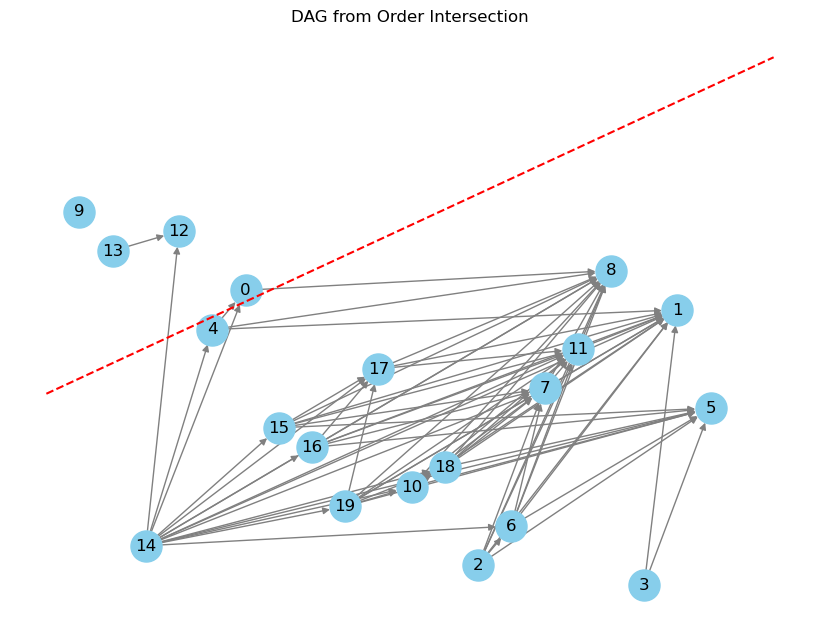

[1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0]


In [50]:
from RNG_DAG import DAG

# create a random DAG
dag = DAG(20)
solutions = dag.get_counts()
print(solutions)

# create an adjacency matrix from the DAG
adjacency_matrix = dag.get_adjacency_matrix()
print(adjacency_matrix)

slope, intercept = dag.get_slope_intercept()

dag.plot_dag(slope=slope, intercept=intercept)
print(dag.h)


# Testing the 3-chain

{'3-chains': 43, 'diamonds': 24, 'bh-links': 0}


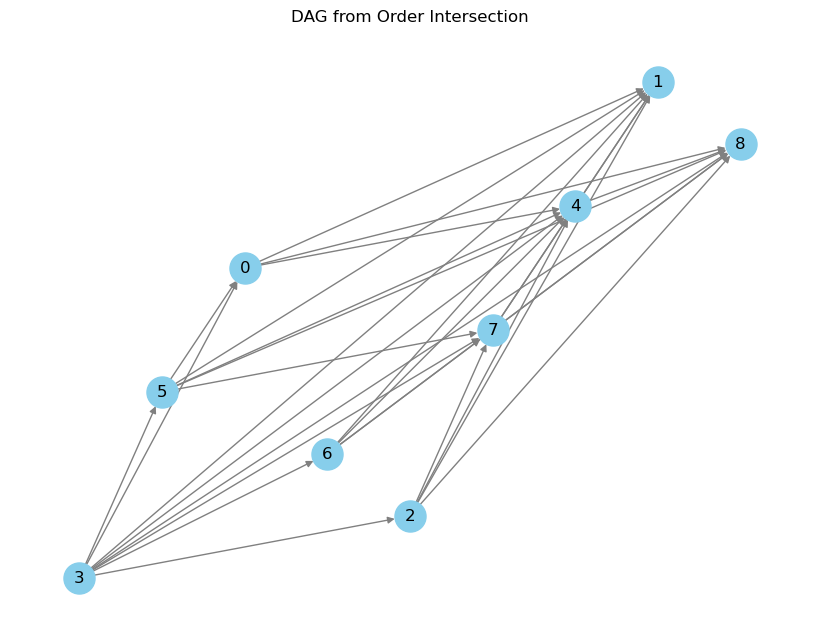

array([[0., 1., 0., 0., 1., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 1., 0., 0., 1., 1.],
       [1., 1., 1., 0., 1., 1., 1., 1., 1.],
       [0., 1., 0., 0., 0., 0., 0., 0., 1.],
       [1., 1., 0., 0., 1., 0., 0., 1., 1.],
       [0., 1., 0., 0., 1., 0., 0., 1., 1.],
       [0., 1., 0., 0., 1., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [11]:
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem

# create a random DAG
tc_N = 9
tc_dag = DAG(tc_N)
tc_solutions = tc_dag.get_counts()
print(tc_solutions)

tc_dag.plot_dag()
tc_dag.get_adjacency_matrix()

In [12]:
from QUBO_FUNCTIONS import QUBO_Problem
from VQALib import CubicProgram, IsingHamiltonian

# create a QUBO problem
three_chain_problem = QUBO_Problem(tc_dag.get_adjacency_matrix(), tc_N, "three-chain")

three_chain_program = CubicProgram(three_chain_problem.linear, three_chain_problem.quadratic, [], 2*tc_N)

three_chain_ising = IsingHamiltonian(three_chain_program)
print(f"Number of linear terms: {len(three_chain_program.linear)}, number of quadratic terms: {len(three_chain_program.quadratic)}")


Number of linear terms: 15, number of quadratic terms: 9


In [13]:
correct_bitstring, probability = three_chain_ising.run_numpy_eigensolver()


Correct bitstring: [1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 0. 1. 1. 1. 1. 1.]
Found bitstring:   [1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1], probability: 0.006903839111328125, overlap: 7.62939453125e-06
101101100110010001: 18098
101101100111010001: 14739
101101100110010101: 14667
101101100111010101: 11812
101101000110010001: 10865
100101100110010001: 10779
101111100110000001: 9052
101101101110010001: 8955
111101100110010001: 8918
100101100110010101: 8728
101101000111010001: 8682
101101101111010001: 7411
101111100110000101: 7397
101111100111000001: 7327
101101101110010101: 7286
111101100111010001: 7245
111101100110010101: 7238
100101000110010001: 6335
101111100111000101: 6070
101101101111010101: 5935
111101100111010101: 5794
101001100110110001: 5440
100101101110010001: 5420
101111000110000001: 5408
100111100110000001: 5353
101101001110010001: 5317
110101100110010001: 5295
111101000110010001: 5168
101101100010010001: 5130
111111100110000001: 4541
111101101110010001: 4510
1011111

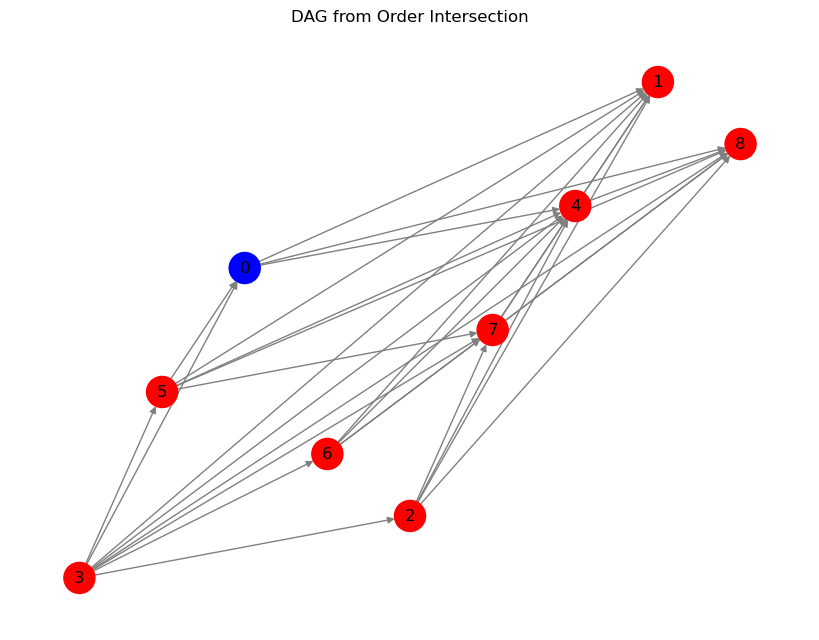

In [14]:
correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
found_bitstring, probability, overlap = three_chain_ising.run_QAOA([correct_bitstring_str], 4)

found_bitstring = found_bitstring[::-1]
print(f"Correct bitstring: {correct_bitstring}")
print(f"Found bitstring:   {found_bitstring}, probability: {probability}, overlap: {overlap}")

# found_bitstring = correct_bitstring

xs = found_bitstring[:len(found_bitstring)//2]
ys = found_bitstring[len(found_bitstring)//2:]
colors = [1 if xs[i] and ys[i] else 0 for i in range(len(xs))]
counts = three_chain_ising.counts
for bitstring in sorted(counts, key=counts.get, reverse=True):
    print(f"{bitstring[::-1]}: {counts[bitstring]}")

tc_dag.color_graph(colors)

### naive approach:

{'3-chains': 58, 'diamonds': 14, 'bh-links': 1}


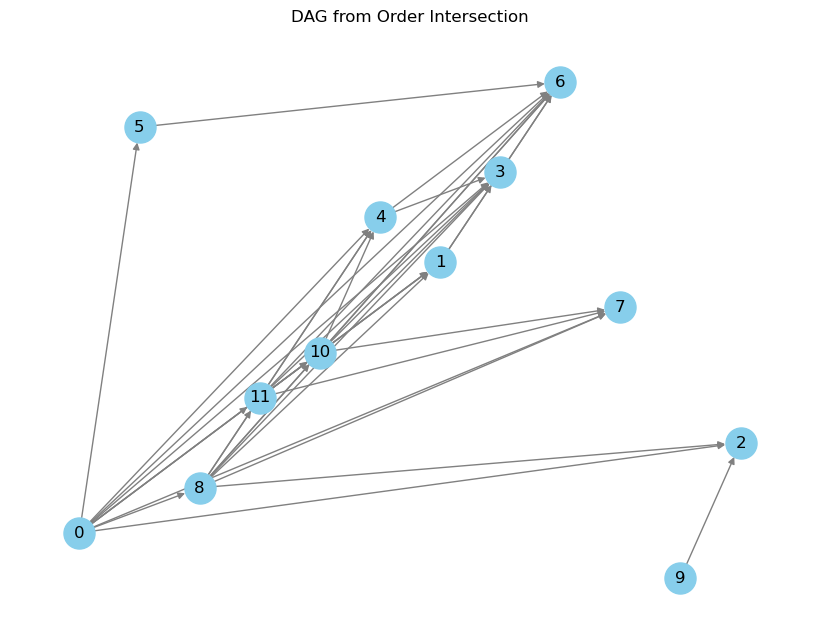

array([[0., 1., 1., 1., 1., 1., 1., 1., 1., 0., 1., 1.],
       [0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 1., 1., 1., 0., 1., 1., 0., 0., 1., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0., 0.],
       [0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 1., 0.]])

In [3]:
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem

# create a random DAG
tcn_N = 12
tcn_dag = DAG(tcn_N)
tcn_solutions = tcn_dag.get_counts()
print(tcn_solutions)

tcn_dag.plot_dag()
tcn_dag.get_adjacency_matrix()

In [4]:
from QUBO_FUNCTIONS import QUBO_Problem
from VQALib import CubicProgram, IsingHamiltonian

# create a QUBO problem
three_chain_naive_problem = QUBO_Problem(tcn_dag.get_adjacency_matrix(), tcn_N, "three-chain-naive")

three_chain_naive_program = CubicProgram(three_chain_naive_problem.linear, three_chain_naive_problem.quadratic, [], tcn_N)

three_chain_naive_ising = IsingHamiltonian(three_chain_naive_program)
print(f"Number of linear terms: {len(three_chain_naive_program.linear)}, number of quadratic terms: {len(three_chain_naive_program.quadratic)}")

Number of linear terms: 12, number of quadratic terms: 23


Correct bitstring: [1. 1. 0. 1. 1. 0. 0.]
Found bitstring:   [1, 1, 0, 1, 1, 0, 0], probability: 0.33359375, overlap: 0.33359375
0011011: 427
0010011: 130
0011000: 128
0000011: 121
0011001: 104
0000001: 74
0010000: 65
0010001: 40
0000000: 38
0000010: 22
0001001: 12
0010010: 11
0001000: 11
0011111: 11
1011011: 10
0111011: 8
0000111: 5
1000000: 4
0010111: 4
1010011: 4
0000110: 3
0111001: 3
0110000: 3
0011101: 3
0000101: 3
1011000: 3
0100010: 3
1011001: 3
0110001: 2
1000001: 2
1000011: 2
0010100: 2
0000100: 2
0011010: 2
0100000: 2
1111011: 1
1001000: 1
0110111: 1
0110011: 1
1010010: 1
0001011: 1
0100011: 1
0010101: 1
1011100: 1
0011100: 1
0111000: 1
1010111: 1
1010000: 1
['b', 'b', 'r', 'b', 'b', 'r', 'r']


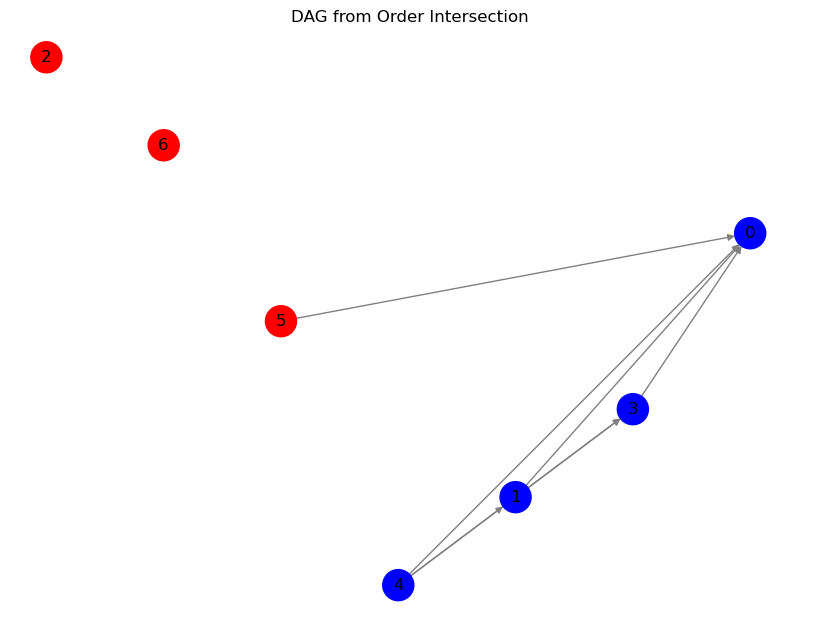

In [32]:
correct_bitstring, probability = three_chain_naive_ising.run_numpy_eigensolver()
correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
found_bitstring, probability, overlap = three_chain_naive_ising.run_QAOA_custom([correct_bitstring_str], 4)

found_bitstring = found_bitstring[::-1]
print(f"Correct bitstring: {correct_bitstring}")
print(f"Found bitstring:   {found_bitstring}, probability: {probability}, overlap: {overlap}")
# counts is a dictionary with the bitstrings as keys and the number of times they were found as values
# print the bitstrings and their counts in descending order
counts = three_chain_naive_ising.counts
for bitstring in sorted(counts, key=counts.get, reverse=True):
    print(f"{bitstring}: {counts[bitstring]}")

colors = [1 if found_bitstring[i] else 0 for i in range(len(found_bitstring))]

tcn_dag.color_graph(colors)

### naive 2:

{'3-chains': 16, 'diamonds': 8, 'bh-links': 1}


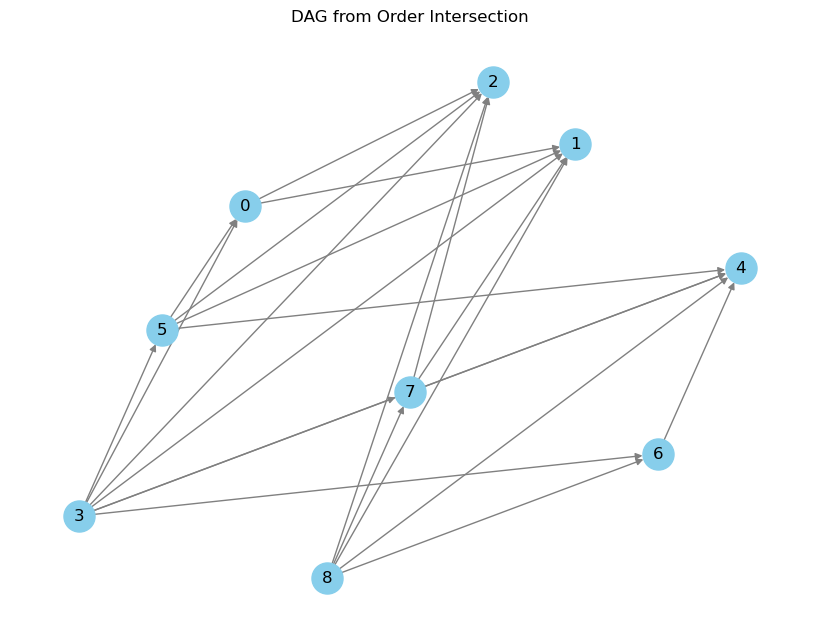

array([[0., 1., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 0., 1., 1., 1., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 1., 0., 1., 0., 0., 0., 0.],
       [0., 1., 1., 0., 1., 0., 1., 1., 0.]])

In [8]:
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem

# create a random DAG
tcn2_N = 9
tcn2_dag = DAG(tcn2_N)
tcn2_solutions = tcn2_dag.get_counts()
print(tcn2_solutions)

tcn2_dag.plot_dag()
tcn2_dag.get_adjacency_matrix()


In [21]:

from QUBO_FUNCTIONS import QUBO_Problem
from VQALib import CubicProgram, IsingHamiltonian

# create a QUBO problem
three_chain_naive_2_problem = QUBO_Problem(tcn2_dag.get_adjacency_matrix(), tcn2_N, "three-chain-naive-2")

three_chain_naive_2_program = CubicProgram(three_chain_naive_2_problem.linear, three_chain_naive_2_problem.quadratic, [], 2*tcn2_N)

three_chain_naive_2_ising = IsingHamiltonian(three_chain_naive_2_program)
print(f"Number of linear terms: {len(three_chain_naive_2_program.linear)}, number of quadratic terms: {len(three_chain_naive_2_program.quadratic)}")


Number of linear terms: 18, number of quadratic terms: 9


In [22]:
correct_bitstring, probability = three_chain_naive_2_ising.run_numpy_eigensolver()


Correct bitstring: [0. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0. 0. 0.]
Found bitstring:   [0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0], probability: 0.0012599945068359375, overlap: 0.0012599945068359375
xs: [0, 0, 0, 1, 0, 1, 0, 0, 1], ys: [1, 1, 1, 0, 1, 0, 0, 0, 0]
000101001111010000: 3303
000101001011010000: 2148
000101011111010000: 1904
010101001111010000: 1856
000101101111010000: 1843
000101001111110000: 1830
100101001111010000: 1829
000101001111011000: 1824
000111001111010000: 1815
001101001111010000: 1815
000101001111010001: 1808
000101001111010010: 1803
000101001111010100: 1770
000101001111000000: 1378
000101000111010000: 1338
001101001011010000: 1269
000101001011010001: 1259
000101001011010010: 1257
000101001011110000: 1228
000111001011010000: 1223
000101001011011000: 1221
000101001011010100: 1220
100101001011010000: 1219
000101011011010000: 1203
010101001011010000: 1202
000101101011010000: 1142
000101001111011010: 1060
010111001111010000: 1058
101101001111010000

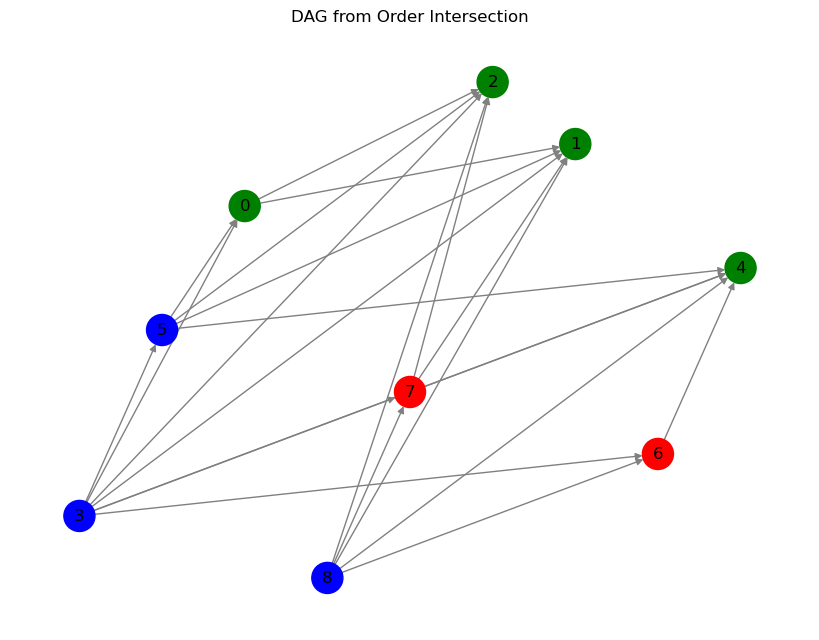

In [24]:
correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
found_bitstring, probability, overlap = three_chain_naive_2_ising.run_QAOA([correct_bitstring_str], 4)

found_bitstring = found_bitstring[::-1]
print(f"Correct bitstring: {correct_bitstring}")
print(f"Found bitstring:   {found_bitstring}, probability: {probability}, overlap: {overlap}")

xs = found_bitstring[:len(found_bitstring)//2]
ys = found_bitstring[len(found_bitstring)//2:]
print(f"xs: {xs}, ys: {ys}")

counts = three_chain_naive_2_ising.counts
for bitstring in sorted(counts, key=counts.get, reverse=True):
    print(f"{bitstring[::-1]}: {counts[bitstring]}")

colors1 = [1 if xs[i] else 0 for i in range(len(xs))]
colors2 = [1 if ys[i] else 0 for i in range(len(ys))]

tcn2_dag.color_graph(colors1, colors2)

# Testing the 2-link:

{'3-chains': 0, 'diamonds': 0, 'bh-links': 1}


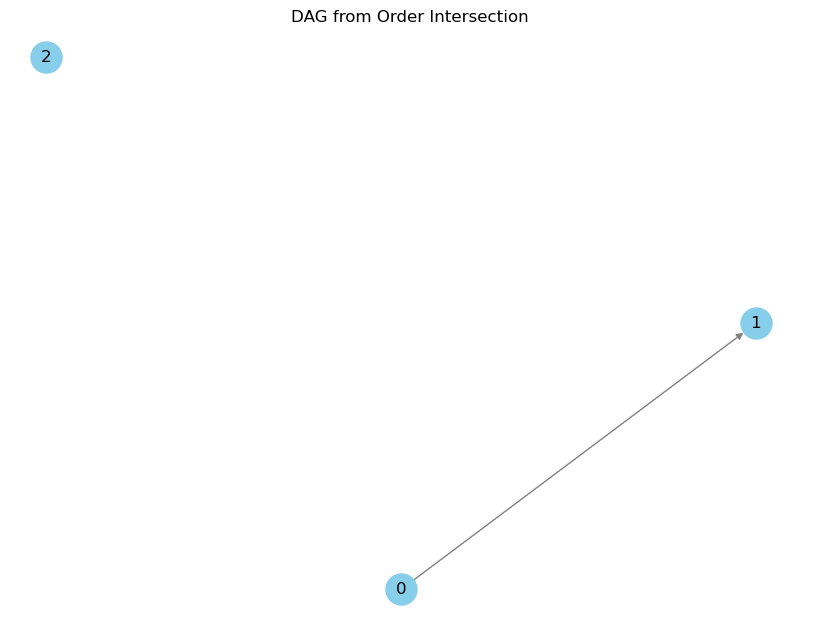

array([[0., 1., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [31]:
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem

# create a random DAG
tl_N = 3
tl_dag = DAG(tl_N)
tl_solutions = tl_dag.get_counts()
print(tl_solutions)

tl_dag.plot_dag()
tl_dag.get_adjacency_matrix()

In [33]:
from QUBO_FUNCTIONS import QUBO_Problem
from VQALib import CubicProgram, IsingHamiltonian

# create a QUBO problem
two_link_problem = QUBO_Problem(tl_dag.get_adjacency_matrix(), tl_N, "two-link-simple")

two_link_program = CubicProgram(two_link_problem.linear, two_link_problem.quadratic, [], 3*tl_N*tl_N)

two_link_ising = IsingHamiltonian(two_link_program)

In [34]:
correct_bitstring, probability = two_link_ising.run_numpy_eigensolver()
print(f"Correct bitstring: {correct_bitstring}")
found_bitstring = correct_bitstring

# found_bitstring, probability, overlap = two_link_ising.run_QAOA(correct_bitstring, 4)
# print(f"Correct bitstring: {correct_bitstring}")
# print(f"Found bitstring:   {found_bitstring}, probability: {probability}, overlap: {overlap}")

xs = found_bitstring[:len(found_bitstring)//3]
ys = found_bitstring[len(found_bitstring)//3:2*len(found_bitstring)//3]
zs = found_bitstring[2*len(found_bitstring)//3:]

for i in range(tl_N):
    for j in range(tl_N):
        if zs[i+j*tl_N]:
            colors[i] = 1
            colors[j] = 1
# colors = [zs[i]%tl_N for i in range(len(zs))]
print(colors)

dag.color_graph(colors[::-1])

Correct bitstring: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
[0, 0, 0, 1, 0, 0, 0]


NameError: name 'dag' is not defined

In [35]:
tl_dag.color_graph(colors)

IndexError: list assignment index out of range

# Testing black hole links:

{'3-chains': 3, 'diamonds': 1, 'bh-links': 2}


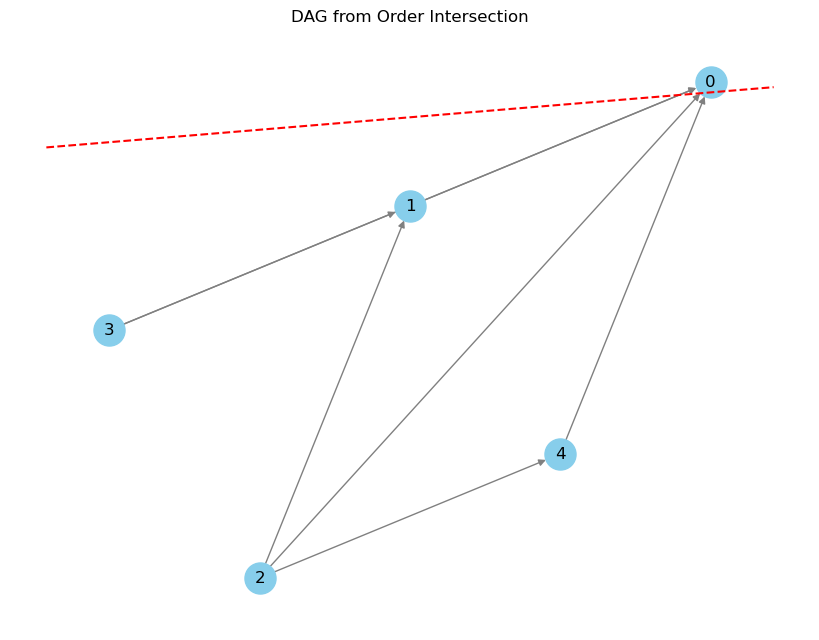

In [6]:
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem

# create a random DAG
bh_dag = DAG(5)
bh_solutions = bh_dag.get_counts()
print(bh_solutions)

slope, intercept = bh_dag.get_slope_intercept()
bh_dag.plot_dag(slope=slope, intercept=intercept)

In [7]:
bh_problem = QUBO_Problem(bh_dag.get_adjacency_matrix(), 5, "bh-links", bh_dag.h)

bh_cubic_program = CubicProgram(bh_problem.linear, bh_problem.quadratic, [], 2*bh_dag.N)

bh_hamiltonian = IsingHamiltonian(bh_cubic_program)

In [8]:
bh_dag.get_adjacency_matrix()
bh_dag.h

[1, 0, 0, 0, 0]

In [9]:
correct_bitstring, probability = bh_hamiltonian.run_numpy_eigensolver()
correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
print(f"Correct bitstring: {correct_bitstring}")


Correct bitstring: [1. 0. 0. 0. 0. 0. 1. 0. 0. 1.]


Correct bitstring: [1. 0. 0. 0. 0. 0. 1. 0. 0. 1.]
Found bitstring:   [1, 0, 0, 0, 0, 0, 1, 0, 0, 1], probability: 0.1642578125, overlap: 0.1642578125
1001000001: 1682
1001001001: 542
1101000000: 497
1001000000: 417
1000000001: 384
0001000001: 378
1101000001: 289
0100000000: 257
1011000000: 250
1001000011: 194
1001010001: 189
0000000001: 187
1101001000: 164
1001100001: 162
1001001000: 152
0111000000: 130
1000001001: 124
0001000000: 116
1110000000: 110
0001001001: 102
1100000001: 96
0101000001: 94
1101001001: 94
1000000000: 88
1111000001: 87
0100001000: 85
0010000000: 79
1011000001: 77
0000000000: 76
0100000001: 74
0110000000: 64
1010000001: 63
1011001000: 62
1001011001: 57
1001101001: 52
1101100000: 52
1001001011: 50
1000000011: 49
1001010000: 48
1000100001: 46
1101000010: 45
0011000001: 45
1001000010: 43
0001000011: 42
1001100000: 42
1111000000: 41
0001100001: 41
1110001000: 40
0000001001: 40
1101010000: 38
1000010001: 38
1000001000: 37
1101100001: 36
1100001001: 35
1011001001: 35
010

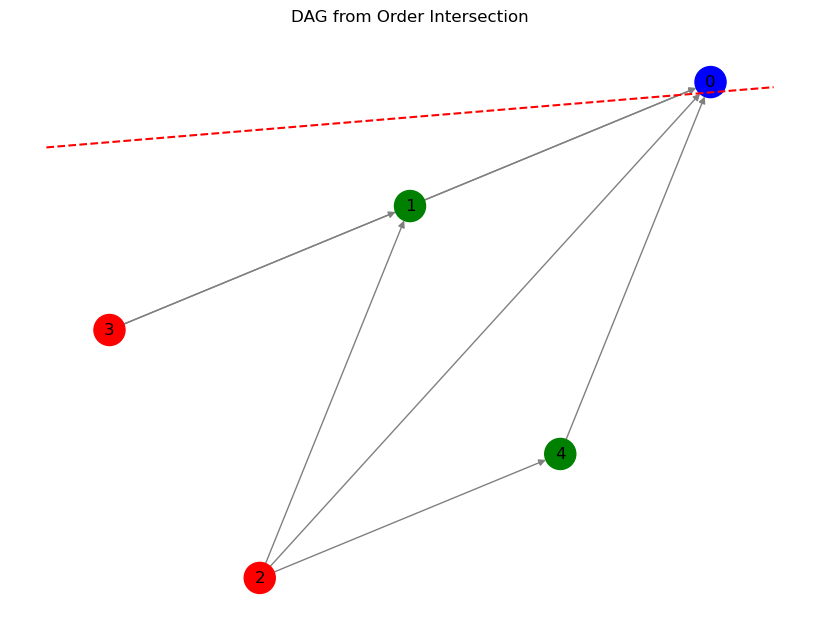

In [10]:

found_bitstring, probability, overlap = bh_hamiltonian.run_QAOA([correct_bitstring_str], 4)

found_bitstring = found_bitstring[::-1]
print(f"Correct bitstring: {correct_bitstring}")
print(f"Found bitstring:   {found_bitstring}, probability: {probability}, overlap: {overlap}")

counts = bh_hamiltonian.counts
for bitstring in sorted(counts, key=counts.get, reverse=True):
    print(f"{bitstring}: {counts[bitstring]}")
xs = found_bitstring[:len(found_bitstring)//2]
ys = found_bitstring[len(found_bitstring)//2:]
print(f"xs: {xs},\nys: {ys}")

colors1 = [1 if xs[i] else 0 for i in range(len(xs))]
colors2 = [1 if ys[i] else 0 for i in range(len(ys))]

bh_dag.color_graph(colors1, colors2, slope, intercept)

['b', 'r', 'r', 'g', 'g']


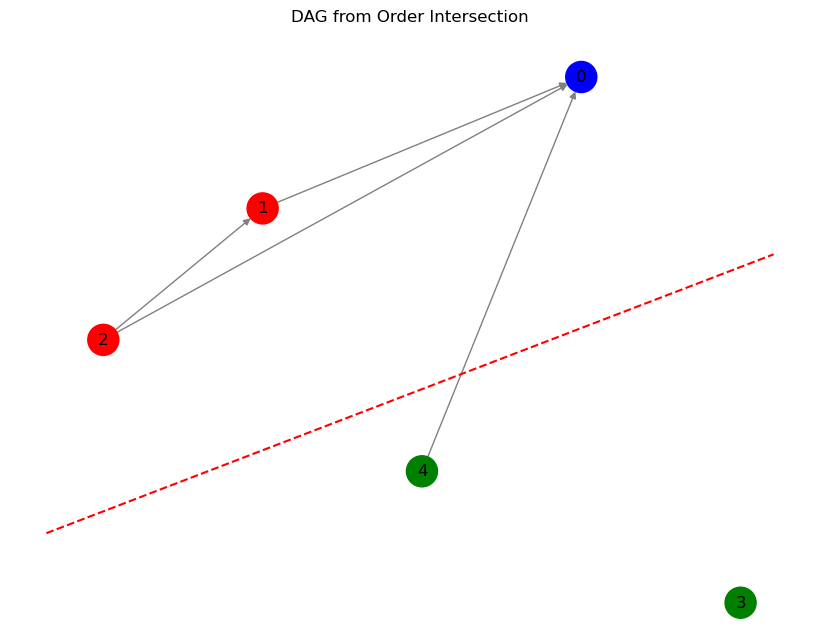

In [15]:
bh_dag.color_graph(xs, ys, bh_dag.slope, bh_dag.intercept)

In [ ]:
found_bitstring, probability, overlap = bh_hamiltonian.run_VQE([1 for i in range(3*bh_dag.N)], 4)
print(found_bitstring, probability)
found_bitstring = found_bitstring
xs = found_bitstring[:len(found_bitstring)//3]
ys = found_bitstring[len(found_bitstring)//3:2*len(found_bitstring)//3]
zs = found_bitstring[2*len(found_bitstring)//3:]

print(xs)
print(ys)

[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1] 0.433160400390625
[1, 0, 0, 0, 0]
[0, 0, 0, 0, 0]


['r', 'b', 'r', 'g', 'r']


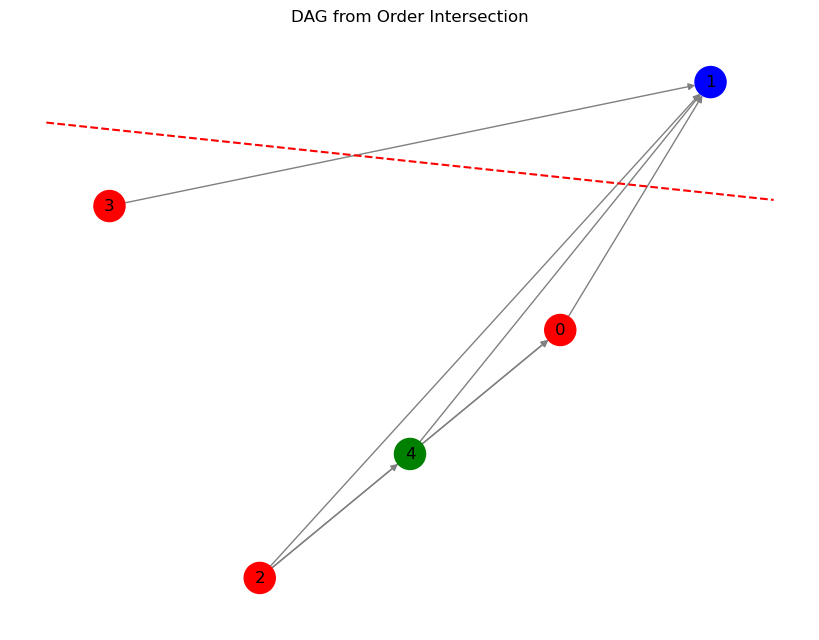

In [23]:
bh_dag.color_graph(xs, ys, bh_dag.slope, bh_dag.intercept)

In [10]:
found_bitstring, probability = bh_hamiltonian.run_numpy_eigensolver()
print(found_bitstring, probability)
found_bitstring = found_bitstring
xs = found_bitstring[:len(found_bitstring)//3]
ys = found_bitstring[len(found_bitstring)//3:2*len(found_bitstring)//3]
zs = found_bitstring[2*len(found_bitstring)//3:]

print(xs)
print(ys)

[1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0.] 1.0
[1. 0. 0. 0. 0.]
[0. 0. 0. 0. 1.]


{'pos': (3, 4)} 0
{'pos': (1, 3)} 1
{'pos': (0, 2)} 2
{'pos': (4, 0)} 3
{'pos': (2, 1)} 4
['b', 'r', 'r', 'r', 'g']


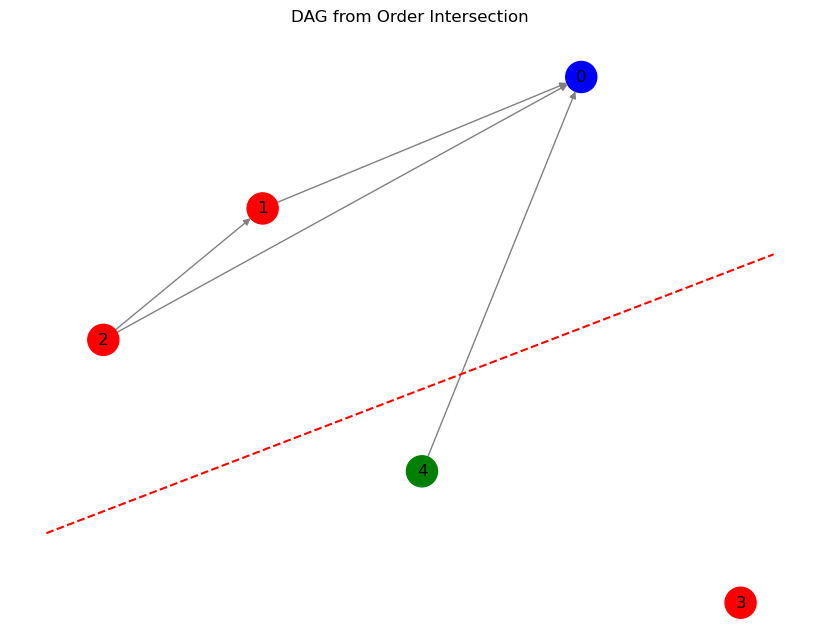

In [11]:
for vertex in bh_dag.G_tc.nodes:
    print(bh_dag.G_tc.nodes[vertex], vertex)

bh_dag.color_graph(xs, ys, bh_dag.slope, bh_dag.intercept)

In [27]:
print(bh_dag.h)
bh_dag.get_adjacency_matrix()

[0, 1, 0, 0, 0]


array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [1., 1., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [1., 1., 0., 0., 0.]])

# Testing noisy simulation

In [5]:
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
from qiskit.providers.fake_provider import FakeAthens
from qiskit_aer import AerSimulator
from qiskit.circuit.library import QAOAAnsatz

backend = FakeAthens()
noise_model = NoiseModel.from_backend(backend)

aer_simulator_ideal = AerSimulator(method="statevector")
aer_simulator_noisy = AerSimulator(noise_model=noise_model, method="statevector")

In [8]:
# ideal simulation:
def ideal_sim(graph, parameters, function, qubit_mult):
    problem = QUBO_Problem(graph.get_adjacency_matrix(), graph.N, function)
    program = CubicProgram(problem.linear, problem.quadratic, [], qubit_mult*graph.N)
    hamiltonian = IsingHamiltonian(program)

    correct_bitstring, _ = hamiltonian.run_numpy_eigensolver()
    correct_bitstrings = ["".join([str(int(x)) for x in correct_bitstring[::-1]])]

    qaoa_ansatz = QAOAAnsatz(hamiltonian.qubit_op, reps=4)
    qaoa_ansatz.measure_active()

    parameter_bindings = dict(zip(qaoa_ansatz.parameters, parameters))
    qaoa_with_parameters = qaoa_ansatz.assign_parameters(parameter_bindings)
    qaoa_with_parameters_decomposed = qaoa_with_parameters.decompose(reps=3)

    number_of_shots = 10*pow(2, hamiltonian.qubit_op.num_qubits)
    counts = aer_simulator_ideal.run(qaoa_with_parameters_decomposed, shots=number_of_shots).result().get_counts()

    probabilities = {bitstring: (count/number_of_shots) \
                                for bitstring, count in counts.items()}
    correct_prob = 0
    for correct_bitstring in correct_bitstrings:
        if correct_bitstring in probabilities.keys():
            correct_prob += probabilities[correct_bitstring]
    if correct_prob == 0:
        correct_prob = 1/(2*pow(2, hamiltonian.qubit_op.num_qubits))

    return correct_prob

def noisy_sim(graph, parameters, function, qubit_mult):
    problem = QUBO_Problem(graph.get_adjacency_matrix(), graph.N, function)
    program = CubicProgram(problem.linear, problem.quadratic, [], qubit_mult*graph.N)
    hamiltonian = IsingHamiltonian(program)

    correct_bitstring, _ = hamiltonian.run_numpy_eigensolver()
    correct_bitstrings = ["".join([str(int(x)) for x in correct_bitstring[::-1]])]

    qaoa_ansatz = QAOAAnsatz(hamiltonian.qubit_op, reps=4)
    qaoa_ansatz.measure_active()

    parameter_bindings = dict(zip(qaoa_ansatz.parameters, parameters))
    qaoa_with_parameters = qaoa_ansatz.assign_parameters(parameter_bindings)
    qaoa_with_parameters_decomposed = qaoa_with_parameters.decompose(reps=3)

    number_of_shots = 10*pow(2, hamiltonian.qubit_op.num_qubits)
    counts = aer_simulator_noisy.run(qaoa_with_parameters_decomposed, shots=number_of_shots).result().get_counts()

    probabilities = {bitstring: (count/number_of_shots) \
                                for bitstring, count in counts.items()}
    correct_prob = 0
    for correct_bitstring in correct_bitstrings:
        if correct_bitstring in probabilities.keys():
            correct_prob += probabilities[correct_bitstring]
    if correct_prob == 0:
        correct_prob = 1/(2*pow(2, hamiltonian.qubit_op.num_qubits))

    return correct_prob

In [23]:
import pickle

parameters = [-2.54630331,  1.36924767, -2.86133025,  1.84223595, -0.44556164,  6.26947132, -0.28154989,  2.35246692]

# retrieve a size 7 graph from saved graphs:
size_7_graphs = []
with open("generated_graphs/dags_7.pkl", "rb") as f:
    size_7_graphs = pickle.load(f)
    
dag = size_7_graphs[3]

ideal_correct_prob = ideal_sim(dag, parameters, "three-chain", 2)
ideal_correct_prob

0.000775146484375

In [20]:
noisy_correct_prob = noisy_sim(dag, parameters, "three-chain", 2)
noisy_correct_prob

0.000885009765625

# Producing figures:

In [ ]:
# Figure showing success of three-chain problem on size 7 graph
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
bar_width = 0.35
bar1 = ax.bar(0, ideal_correct_prob, bar_width, label="Ideal")
bar2 = ax.bar(1, noisy_correct_prob, bar_width, label="Noisy")
